## Predicción 2019, diagnóstico e incertidumbre

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from modeling import (load_data, make_final_split, make_ridge, make_tree, make_rf,
                      evaluate_predictions, TARGET, COUNTRIES, RESULTS_DIR, FIGURES_DIR)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = load_data()
final_train, test_df = make_final_split(df)

print("Entrenamiento final:", len(final_train), "filas |",
      final_train["utc_timestamp"].min(), "→", final_train["target_timestamp"].max())
print("Reserva 2019:", len(test_df), "filas")
display(pd.DataFrame({
    "train": final_train.groupby("country").size(),
    "test": test_df.groupby("country").size(),
    "test_total_2019": df[df.period == "holdout"].groupby("country").size(),
}).assign(test_excluidas=lambda d: d.test_total_2019 - d.test))

Entrenamiento final: 103680 filas | 2015-01-07 23:00:00+00:00 → 2018-12-31 23:00:00+00:00
Reserva 2019: 26031 filas


,train,test,test_total_2019,test_excluidas
country,,,,
DE,34873,8736,8760,24
ES,34651,8736,8760,24
FR,34156,8559,8760,201


## Ajuste final y predicción sobre la reserva

In [2]:
fit_times = {}
test_df["pred_persistence"] = test_df["demand_mw"]
test_df["pred_weekly"] = test_df["lag_168h"]

for name, factory, kw, col in [("Ridge", make_ridge, {}, "pred_ridge"),
                               ("Decision Tree", make_tree, {}, "pred_tree"),
                               ("Random Forest (dummy)", make_rf, {"calendar": "dummy"}, "pred_rf_dummy"),
                               ("Random Forest", make_rf, {"calendar": "cyclic"}, "pred_rf")]:
    model, feats = factory(**kw)
    t0 = time.perf_counter()
    model.fit(final_train[feats], final_train[TARGET])
    fit_times[name] = time.perf_counter() - t0
    test_df[col] = model.predict(test_df[feats])
    print(f"{name}: ajuste {fit_times[name]:.1f} s")

pred_cols = ["utc_timestamp", "target_timestamp", "target_local_timestamp", "country", TARGET,
             "pred_persistence", "pred_weekly", "pred_ridge", "pred_tree", "pred_rf_dummy", "pred_rf"]
test_df[pred_cols].to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

Ridge: ajuste 0.1 s


Decision Tree: ajuste 88.1 s


Random Forest (dummy): ajuste 754.3 s


Random Forest: ajuste 45.0 s


## Métricas en la reserva: MAE, RMSE y NMAE por país

El NMAE de cada país usa como escala la demanda media del **entrenamiento final** (2015–2018).

In [3]:
MODELS = {"Persistence": "pred_persistence", "Weekly Seasonal": "pred_weekly",
          "Ridge": "pred_ridge", "Decision Tree": "pred_tree",
          "Random Forest (dummy)": "pred_rf_dummy", "Random Forest": "pred_rf"}

test_results = pd.concat([
    evaluate_predictions(final_train, test_df, test_df[col], name, "Test 2019")
    for name, col in MODELS.items()
], ignore_index=True)
test_results.to_csv(RESULTS_DIR / "test_results.csv", index=False)

macro_test = (test_results[test_results.country == "Macro"]
              .set_index("model")["NMAE"].sort_values())
macro_test.to_frame("NMAE macro 2019").round(5)

,NMAE macro 2019
model,
Random Forest,0.02493
Random Forest (dummy),0.02616
Decision Tree,0.03325
Ridge,0.04098
Weekly Seasonal,0.05047
Persistence,0.06700


In [4]:
# Tabla principal: modelo elegido (RF cíclico) vs. referencia, por país
rf = test_results[test_results.model == "Random Forest"].set_index("country")
ref = test_results[test_results.model == "Weekly Seasonal"].set_index("country")
main_table = pd.DataFrame({
    "n": rf["n"],
    "MAE RF (MW)": rf["MAE"], "MAE ref (MW)": ref["MAE"],
    "RMSE RF (MW)": rf["RMSE"], "RMSE ref (MW)": ref["RMSE"],
    "NMAE RF": rf["NMAE"], "NMAE ref": ref["NMAE"],
})
main_table["Δ MAE (MW)"] = main_table["MAE RF (MW)"] - main_table["MAE ref (MW)"]
main_table["Mejora NMAE %"] = 100 * (1 - main_table["NMAE RF"] / main_table["NMAE ref"])
main_table.to_csv(RESULTS_DIR / "test_main_table.csv")
main_table.round(4)

,n,MAE RF (MW),MAE ref (MW),RMSE RF (MW),RMSE ref (MW),NMAE RF,NMAE ref,Δ MAE (MW),Mejora NMAE %
country,,,,,,,,,
DE,8736,1353.9073,2559.4958,2225.3169,4469.0195,0.0242,0.0458,-1205.5885,47.1026
ES,8736,585.9180,1255.4279,1019.5936,2002.3416,0.0204,0.0437,-669.5099,53.3292
FR,8559,1626.3202,3337.3153,2410.2165,4635.1509,0.0301,0.0618,-1710.9951,51.2686
Macro,26031,NaN,NaN,NaN,NaN,0.0249,0.0505,NaN,50.6026


In [5]:
# Desarrollo (promedio W1-W3) vs. reserva
dev = pd.read_csv(RESULTS_DIR / "global_comparison.csv").set_index("model")["Mean NMAE"]
dev = dev.rename({"Random Forest": "Random Forest (dummy)"})
sens = pd.read_csv(RESULTS_DIR / "sensitivity_results.csv")
dev["Random Forest"] = sens.query("analysis == 'A_calendar' and model == 'Random Forest' "
                                  "and scenario == 'Cíclico' and country == 'Macro'")["NMAE"].mean()
dev_vs_test = pd.DataFrame({"NMAE desarrollo (W1–W3)": dev, "NMAE reserva 2019": macro_test})
dev_vs_test["Cambio %"] = 100 * (dev_vs_test.iloc[:, 1] / dev_vs_test.iloc[:, 0] - 1)
dev_vs_test.sort_values("NMAE reserva 2019").round(5)

,NMAE desarrollo (W1–W3),NMAE reserva 2019,Cambio %
model,,,
Random Forest,0.02712,0.02493,-8.06958
Random Forest (dummy),0.02821,0.02616,-7.26998
Decision Tree,0.03607,0.03325,-7.80868
Ridge,0.04282,0.04098,-4.29079
Weekly Seasonal,0.05374,0.05047,-6.08493
Persistence,0.06792,0.06700,-1.34439


## Diagnóstico de errores

Subgrupos según la **hora objetivo local** de cada país. El umbral de alta demanda es el percentil 90 de la demanda de cada país en el entrenamiento final (no usa datos de 2019).

In [6]:
for name, col in [("rf", "pred_rf"), ("ref", "pred_weekly")]:
    test_df[f"ae_{name}"] = (test_df[TARGET] - test_df[col]).abs()
    test_df[f"err_{name}"] = test_df[col] - test_df[TARGET]   # >0 sobreestima

SEASON = {12: "Invierno", 1: "Invierno", 2: "Invierno", 3: "Primavera", 4: "Primavera",
          5: "Primavera", 6: "Verano", 7: "Verano", 8: "Verano",
          9: "Otoño", 10: "Otoño", 11: "Otoño"}
test_df["season"] = test_df["target_month"].map(SEASON)
test_df["day_type"] = np.where(test_df["target_is_weekend"], "Fin de semana", "Laborable")
p90 = final_train.groupby("country")[TARGET].quantile(0.9)
test_df["high_demand"] = np.where(test_df[TARGET] > test_df["country"].map(p90),
                                  "Alta (>p90)", "Resto")
display(p90.to_frame("umbral p90 (MW)").round(0))

def by_group(g):
    out = (test_df.groupby(["country", g])
           .agg(n=("ae_rf", "size"), MAE_rf=("ae_rf", "mean"), MAE_ref=("ae_ref", "mean"),
                bias_rf=("err_rf", "mean"))
           .reset_index())
    out["Mejora %"] = 100 * (1 - out["MAE_rf"] / out["MAE_ref"])
    out.insert(1, "grupo", g)
    return out.rename(columns={g: "nivel"})

diag = pd.concat([by_group(g) for g in ["day_type", "season", "high_demand"]], ignore_index=True)
diag.to_csv(RESULTS_DIR / "test_diagnostics.csv", index=False)
diag.round(1)

,umbral p90 (MW)
country,
DE,69034.0
ES,34848.0
FR,70770.0


,country,grupo,nivel,n,MAE_rf,MAE_ref,bias_rf,Mejora %
0,DE,day_type,Fin de semana,2496,1025.7,1676.5,-26.6,38.8
1,DE,day_type,Laborable,6240,1485.2,2912.7,-15.2,49.0
2,ES,day_type,Fin de semana,2496,403.2,847.4,22.7,52.4
3,ES,day_type,Laborable,6240,659.0,1418.7,-0.3,53.5
4,FR,day_type,Fin de semana,2448,1475.3,2647.9,-109.8,44.3
5,FR,day_type,Laborable,6111,1686.8,3613.5,-44.6,53.3
6,DE,season,Invierno,2136,1543.1,3343.4,-65.7,53.8
7,DE,season,Otoño,2185,1128.0,1931.0,25.7,41.6
8,DE,season,Primavera,2207,1662.3,2830.8,-130.7,41.3
9,DE,season,Verano,2208,1086.2,2151.9,95.8,49.5


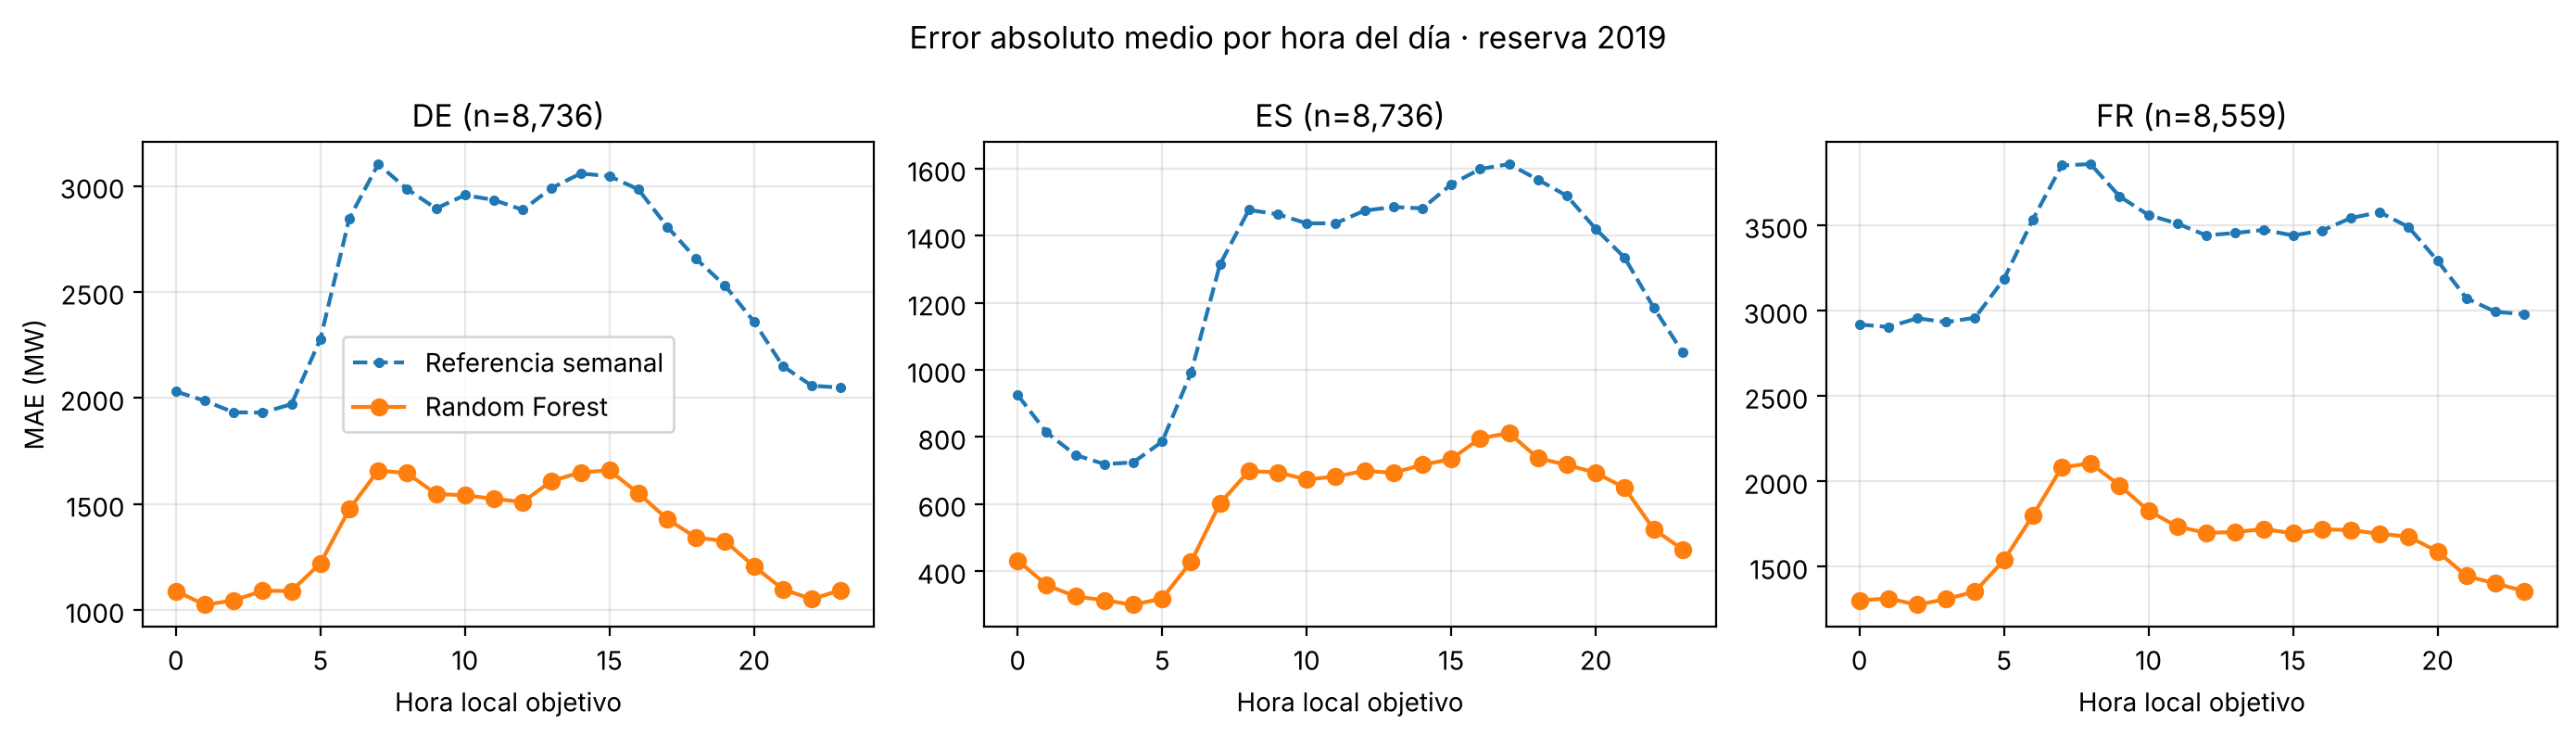

In [7]:
hourly = (test_df.groupby(["country", "target_hour"])[["ae_rf", "ae_ref"]].mean().reset_index())
hourly.to_csv(RESULTS_DIR / "test_error_by_hour.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, c in zip(axes, COUNTRIES):
    h = hourly[hourly.country == c]
    ax.plot(h.target_hour, h.ae_ref, marker=".", ls="--", label="Referencia semanal")
    ax.plot(h.target_hour, h.ae_rf, marker="o", label="Random Forest")
    ax.set_title(f"{c} (n={int((test_df.country == c).sum()):,})")
    ax.set_xlabel("Hora local objetivo")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE (MW)")
axes[0].legend()
fig.suptitle("Error absoluto medio por hora del día · reserva 2019")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "test_mae_by_hour.png", dpi=150)
plt.show()

### Días con mayor error

Se agrupa por día local objetivo para identificar eventos donde el modelo falla. El modelo no incluye feriados.

In [8]:
test_df["target_date"] = test_df["target_local_timestamp"].str[:10]
daily = (test_df.groupby(["country", "target_date"])
         .agg(MAE_rf=("ae_rf", "mean"), MAE_ref=("ae_ref", "mean"), bias_rf=("err_rf", "mean"))
         .reset_index())
worst = (daily.sort_values("MAE_rf", ascending=False).groupby("country").head(6)
         .sort_values(["country", "MAE_rf"], ascending=[True, False]))
worst.to_csv(RESULTS_DIR / "test_worst_days.csv", index=False)
worst.round(0)

,country,target_date,MAE_rf,MAE_ref,bias_rf
274,DE,2019-10-03,11241.0,12150.0,11241.0
119,DE,2019-05-01,11043.0,12761.0,11043.0
107,DE,2019-04-19,10435.0,15033.0,10435.0
159,DE,2019-06-10,8997.0,14446.0,8997.0
0,DE,2019-01-02,8583.0,11077.0,-8433.0
169,DE,2019-06-20,8450.0,7683.0,8450.0
722,ES,2019-12-25,7187.0,10347.0,7187.0
484,ES,2019-05-01,4375.0,5954.0,4375.0
703,ES,2019-12-06,3686.0,2951.0,3610.0
668,ES,2019-11-01,3568.0,4317.0,3566.0


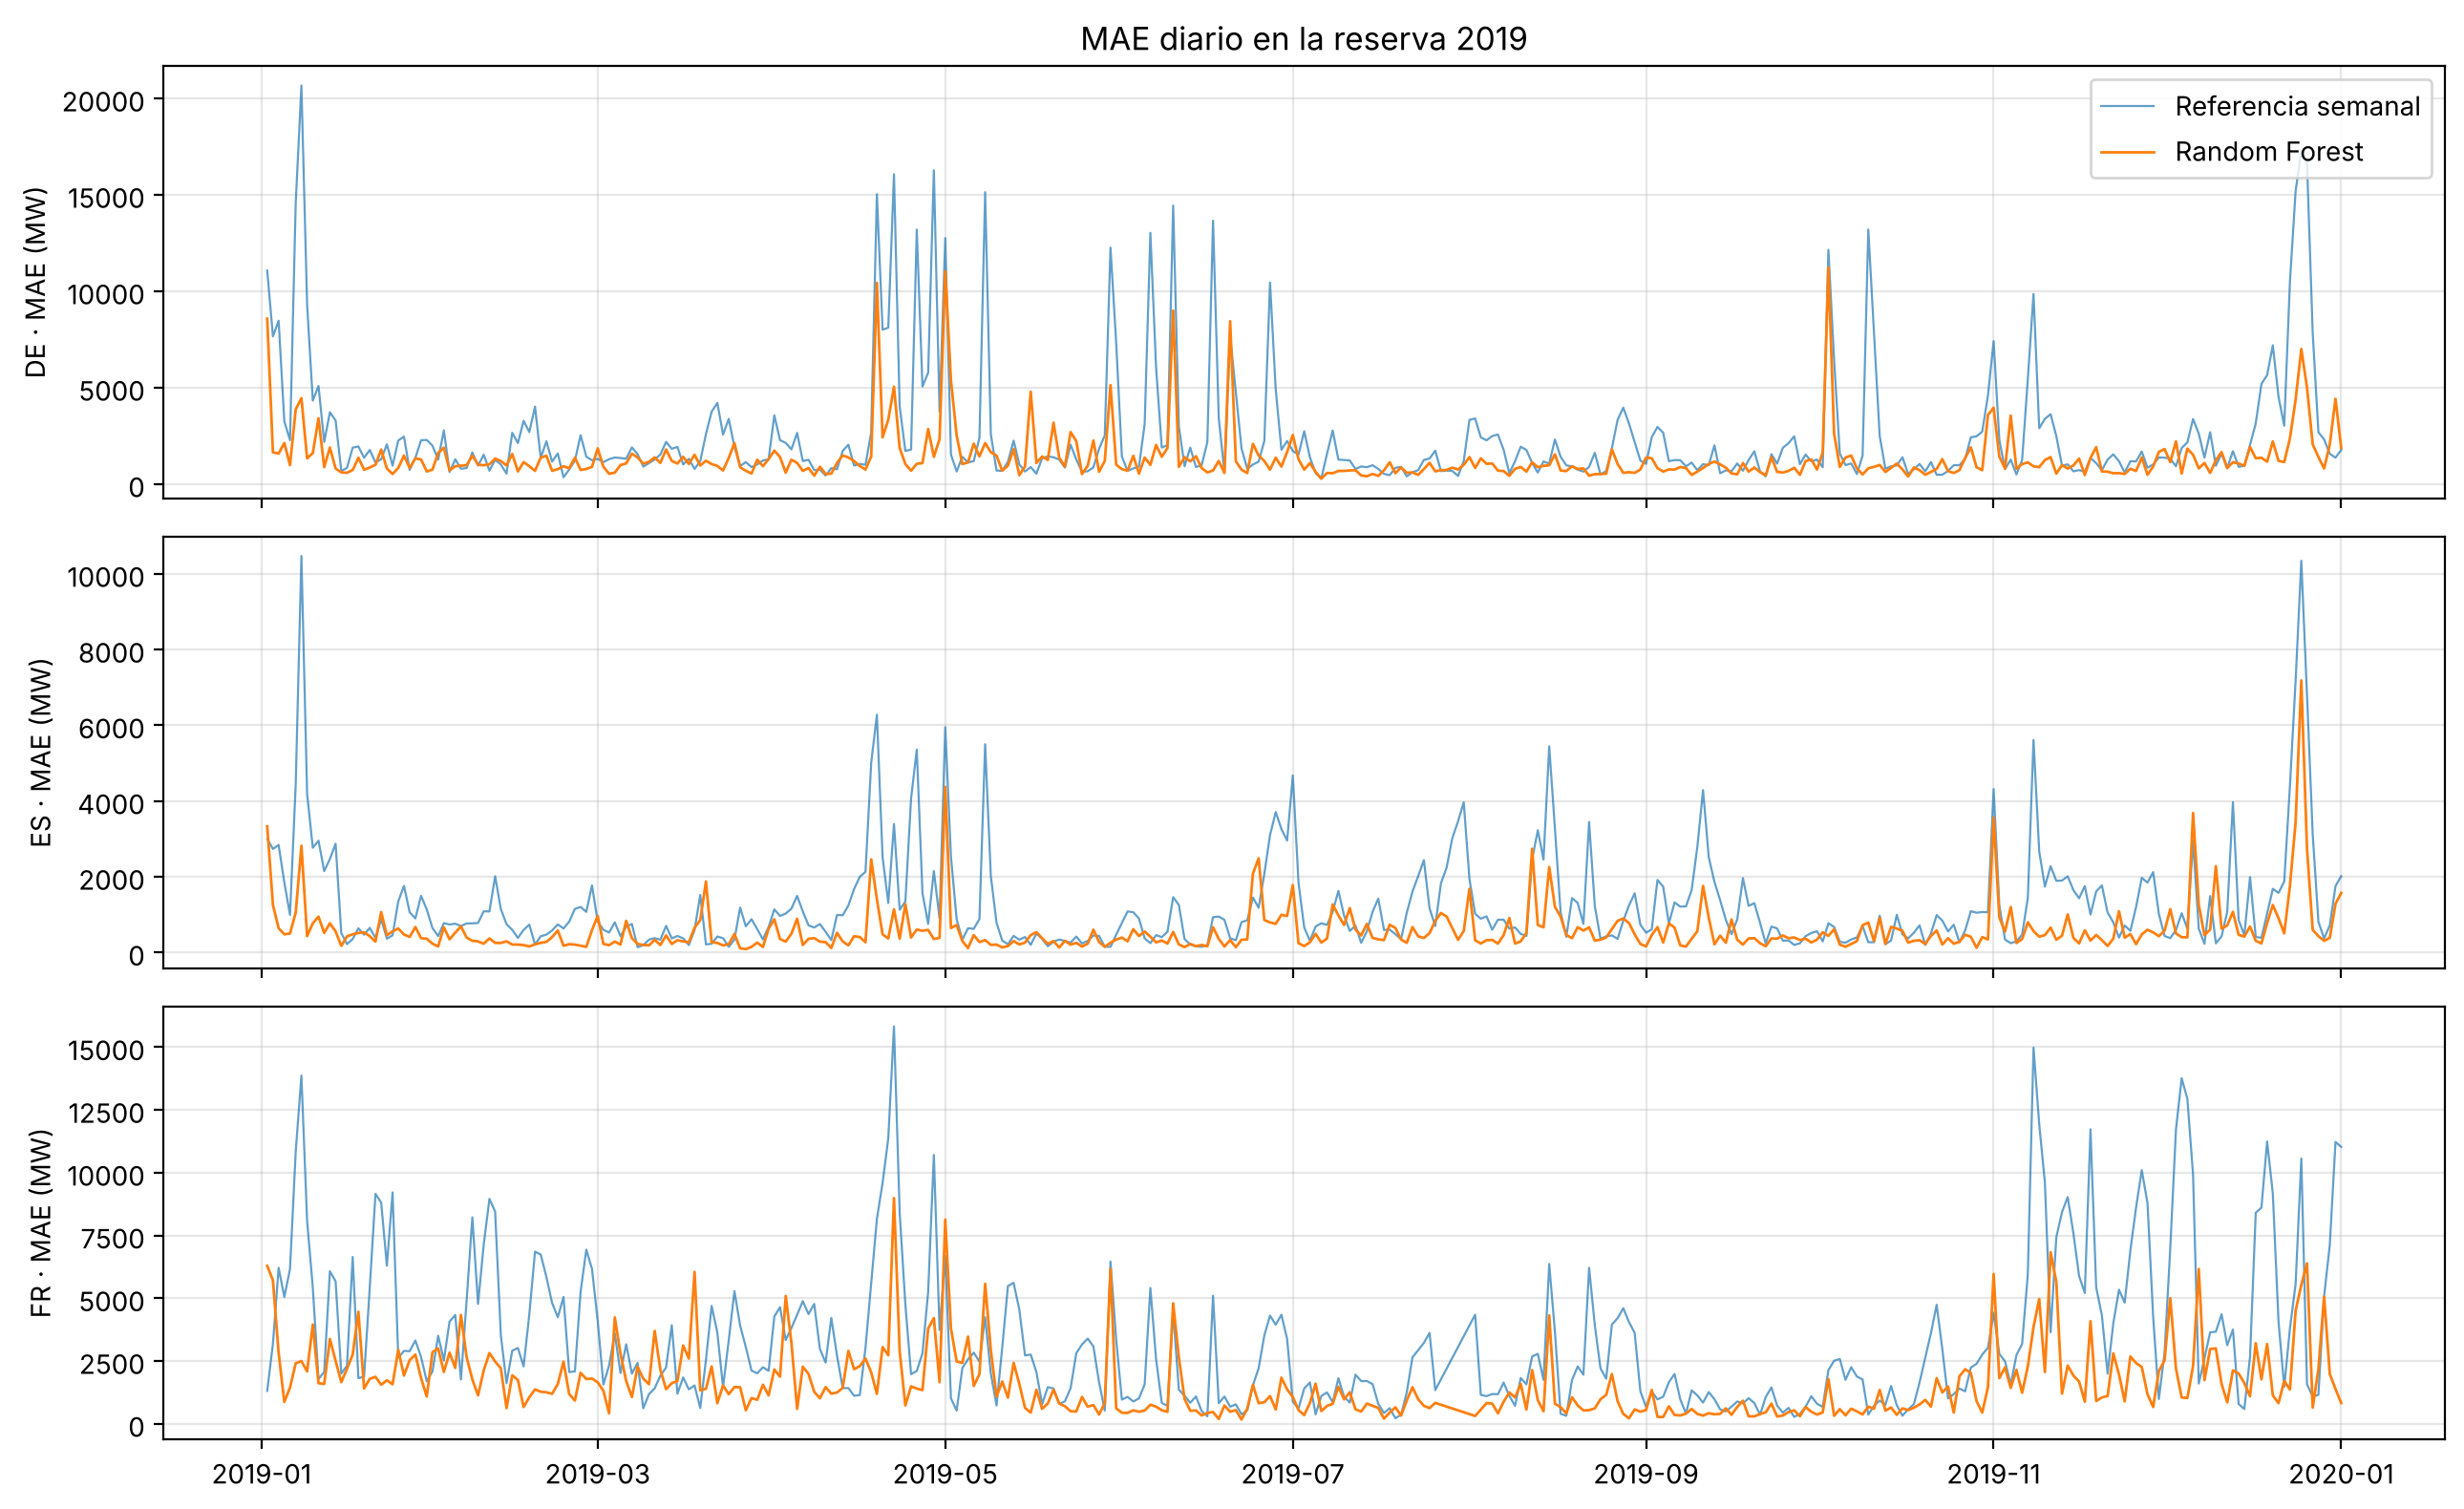

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, c in zip(axes, COUNTRIES):
    d = daily[daily.country == c].copy()
    d["date"] = pd.to_datetime(d.target_date)
    ax.plot(d.date, d.MAE_ref, lw=0.8, alpha=0.7, label="Referencia semanal")
    ax.plot(d.date, d.MAE_rf, lw=1.0, label="Random Forest")
    ax.set_ylabel(f"{c} · MAE (MW)")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right")
axes[0].set_title("MAE diario en la reserva 2019")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "test_mae_daily.png", dpi=150)
plt.show()

## Incertidumbre de la diferencia con la referencia

**Bootstrap por bloques semanales**, con predicciones fijas:

- Unidad remuestreada: semanas de 7 días (UTC) de la reserva. En cada réplica se toman con reemplazo tantas semanas como hay, y **cada semana se toma con los tres países juntos**, conservando la coincidencia de fechas y la dependencia dentro de la semana.
- Estadístico: Δ = NMAE macro (RF) − NMAE macro (referencia). Negativo = RF mejor.
- 2000 réplicas, semilla 42. El modelo **no se reajusta**: el intervalo es condicional a los ajustes realizados y no incluye la incertidumbre de selección ni de entrenamiento.

In [10]:
start = pd.Timestamp("2019-01-01", tz="UTC")
test_df["block"] = (test_df["utc_timestamp"] - start).dt.days // 7
agg = test_df.groupby(["block", "country"]).agg(
    n=("ae_rf", "size"), rf=("ae_rf", "sum"), ref=("ae_ref", "sum"))
N, RF, REF = (agg[c].unstack()[COUNTRIES].fillna(0).to_numpy() for c in ["n", "rf", "ref"])
mu = final_train.groupby("country")[TARGET].mean()[COUNTRIES].to_numpy()
print("Bloques:", N.shape[0])

def stats(idx):
    n = N[idx].sum(0)
    nm_rf, nm_ref = RF[idx].sum(0) / n / mu, REF[idx].sum(0) / n / mu
    return np.r_[nm_rf.mean() - nm_ref.mean(), nm_rf - nm_ref, 1 - nm_rf.mean() / nm_ref.mean()]

observed = stats(np.arange(N.shape[0]))
rng = np.random.default_rng(42)
B = 2000
boot = np.array([stats(rng.integers(0, N.shape[0], N.shape[0])) for _ in range(B)])

labels = ["Δ NMAE macro", "Δ NMAE DE", "Δ NMAE ES", "Δ NMAE FR", "Mejora relativa macro"]
ci = pd.DataFrame({"observado": observed,
                   "IC95 inf": np.percentile(boot, 2.5, axis=0),
                   "IC95 sup": np.percentile(boot, 97.5, axis=0),
                   "P(Δ ≥ 0)": [(boot[:, i] >= 0).mean() if i < 4 else np.nan for i in range(5)]},
                  index=labels)
ci.to_csv(RESULTS_DIR / "test_bootstrap_ci.csv")
ci.round(5)

Bloques: 52


,observado,IC95 inf,IC95 sup,P(Δ ≥ 0)
Δ NMAE macro,-0.02554,-0.03188,-0.02018,0.0
Δ NMAE DE,-0.02159,-0.02984,-0.01476,0.0
Δ NMAE ES,-0.02332,-0.02973,-0.01742,0.0
Δ NMAE FR,-0.03171,-0.03987,-0.02372,0.0
Mejora relativa macro,0.50603,0.45310,0.54827,NaN


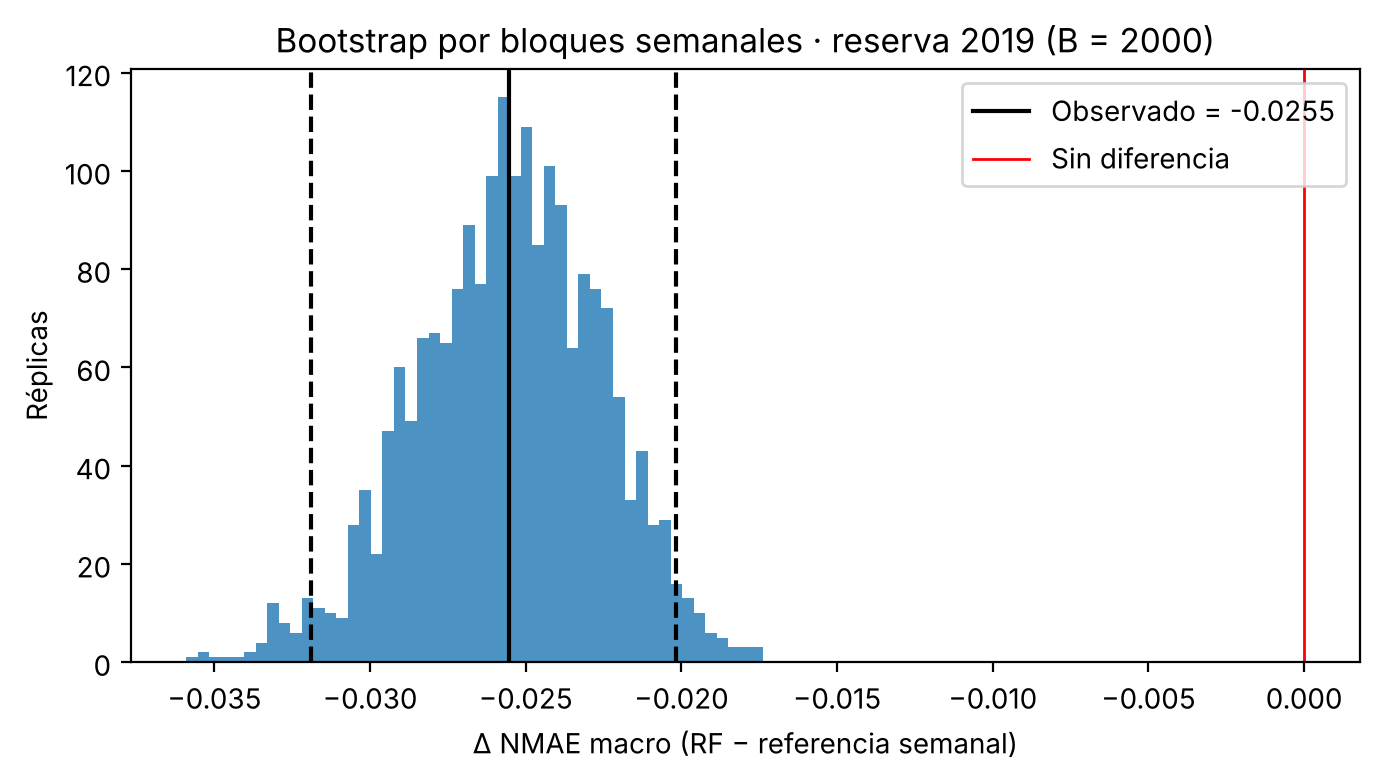

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(boot[:, 0], bins=50, alpha=0.8)
ax.axvline(observed[0], color="k", label=f"Observado = {observed[0]:.4f}")
for q in np.percentile(boot[:, 0], [2.5, 97.5]):
    ax.axvline(q, color="k", ls="--")
ax.axvline(0, color="red", lw=1, label="Sin diferencia")
ax.set_xlabel("Δ NMAE macro (RF − referencia semanal)")
ax.set_ylabel("Réplicas")
ax.set_title("Bootstrap por bloques semanales · reserva 2019 (B = 2000)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "test_bootstrap_delta.png", dpi=150)
plt.show()

In [12]:
pd.Series(fit_times, name="segundos de ajuste final").round(1).to_csv(RESULTS_DIR / "final_fit_times.csv")
pd.Series(fit_times, name="segundos").round(1)

Ridge                      0.1
Decision Tree             88.1
Random Forest (dummy)    754.3
Random Forest             45.0
Name: segundos, dtype: float64

## Síntesis

- **Resultado principal:** en 2019, Random Forest (calendario cíclico) obtiene NMAE macro 0,0249 frente a 0,0505 de la referencia semanal: **−50,6 %** (IC95 bootstrap por bloques: 45,3 %–54,8 %). La mejora es de 47–53 % en cada país y el intervalo de Δ no incluye 0 en ninguno.
- **Desarrollo vs. reserva:** el error en 2019 es igual o menor que en desarrollo para todos los modelos; no hay señales de sobreajuste a las ventanas de validación. El orden de los modelos se mantiene.
- **Subgrupos:** la ventaja se mantiene en laborables, fines de semana, las cuatro estaciones y horas de alta demanda (>p90). En alta demanda el modelo **subestima** (sesgo −460 a −930 MW).
- **Cuándo no confiar:** los peores días son feriados (DE: 3-oct, 1-may, Viernes Santo, Lunes de Pentecostés; ES: 25-dic, 1-may, 6-dic, 1-nov; FR: Lunes de Pascua, 1-may, 11-nov) y los días siguientes a ellos (2-ene, 26-dic). El modelo no tiene variable de feriados y **sobreestima** la demanda esos días por 4 000–11 000 MW de MAE diario.
- **Observación sobre el diseño:** el periodo se define por el origen. Los orígenes del 31-dic-2018 de W3 tienen respuesta el 1-ene-2019; esas 24 respuestas por país de la reserva se usaron como validación en desarrollo (no en entrenamiento). Debe declararse en el informe.